# Question 2

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

### a: Exploring the dataset (data/retail.csv)

In [2]:
retail = pd.read_csv("data/retail.csv")
print("shape:", retail.shape)
print(retail.dtypes)
print("\nQuantity quantiles:")
print(retail["Quantity"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))
print("\nmean:", retail["Quantity"].mean().round(2), "| median:", retail["Quantity"].median())
print("distinct StockCodes:", retail["StockCode"].nunique(), "| distinct CustomerIDs:", retail["CustomerID"].nunique())

shape: (397924, 3)
Quantity        int64
StockCode         str
CustomerID    float64
dtype: object

Quantity quantiles:
0.000        1.0
0.250        2.0
0.500        6.0
0.750       12.0
0.900       24.0
0.990      120.0
0.999      504.0
1.000    80995.0
Name: Quantity, dtype: float64

mean: 13.02 | median: 6.0
distinct StockCodes: 3665 | distinct CustomerIDs: 4339


In [3]:
retail["CustomerID"] = retail["CustomerID"].astype(int).astype(str).astype("category")
retail["StockCode"] = retail["StockCode"].astype("category")
retail["log_quantity"] = np.log(retail["Quantity"])

for col in ["StockCode", "CustomerID"]:
    counts = retail[col].value_counts()
    print(f"{col}: {len(counts)} categories | rows per category: median {int(counts.median())}, "
          f"max {counts.max()} | categories with <=5 rows: {(counts <= 5).sum()} "
          f"| exactly 1 row: {(counts == 1).sum()}")

retail[retail["CustomerID"].isin(["12346", "16446"])]

StockCode: 3665 categories | rows per category: median 49, max 2035 | categories with <=5 rows: 548 | exactly 1 row: 167
CustomerID: 4339 categories | rows per category: median 41, max 7847 | categories with <=5 rows: 300 | exactly 1 row: 72


,Quantity,StockCode,CustomerID,log_quantity
37126,74215,23166,12346,11.214722
133752,1,22980,16446,0.000000
133753,1,22982,16446,0.000000
397451,80995,23843,16446,11.302143


The sum of distinct stock codes and customer IDs is about 8,000, which would make for a very large, sparse matrix if we were to encode this information using one-hot encoding. Some of the large values for quantity have very few order numbers, making it easy to overfit / hard to generalize with this method.

In particular, for the same customer, we can have either only 1 very large order or very few orders with huge variance, making predictions using this method more challenging.

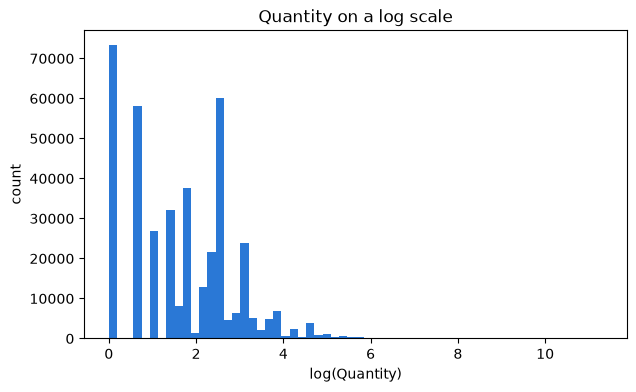

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(retail["log_quantity"], bins=60, color="#2a78d6")
ax.set_xlabel("log(Quantity)")
ax.set_ylabel("count")
ax.set_title("Quantity on a log scale")
plt.show()

As in question 1, we use an 80/10/10 train-validation-test split.

In [5]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(retail, test_size=0.2, random_state=0)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=0)
print("train:", len(train_df), "| validation:", len(val_df), "| test:", len(test_df))

for name, df in [("validation", val_df), ("test", test_df)]:
    unseen_stock = (~df["StockCode"].isin(train_df["StockCode"])).sum()
    unseen_cust = (~df["CustomerID"].isin(train_df["CustomerID"])).sum()
    print(f"{name}: {unseen_stock} rows with a StockCode unseen in training, "
          f"{unseen_cust} rows with an unseen CustomerID")


train: 318339 | validation: 39792 | test: 39793
validation: 26 rows with a StockCode unseen in training, 16 rows with an unseen CustomerID
test: 17 rows with a StockCode unseen in training, 14 rows with an unseen CustomerID


### b: Linear model with target encoding

To reduce the effects of the really large orders, we will, as in question 1, predict log(quantity) and take the error as the squared difference between the predicted and actual log(quantity). We train a linear model here using TargetEncoder from category_encoders, computed using the training data.

In [6]:
# encoding cell

import category_encoders as ce

cat_cols = ["StockCode", "CustomerID"]

encoder = ce.TargetEncoder(cols=cat_cols, min_samples_leaf=20, smoothing=10) # default paprameters
encoder.fit(train_df[cat_cols], train_df["log_quantity"])

X_train = encoder.transform(train_df[cat_cols])
X_val = encoder.transform(val_df[cat_cols])
X_test = encoder.transform(test_df[cat_cols])

y_train = train_df["log_quantity"]
y_val = val_df["log_quantity"]
y_test = test_df["log_quantity"]

print("global mean of log_quantity (training):", round(y_train.mean(), 3))
pd.concat([train_df[cat_cols + ["log_quantity"]], X_train.add_suffix("_enc")], axis=1).head()

global mean of log_quantity (training): 1.648


,StockCode,CustomerID,log_quantity,StockCode_enc,CustomerID_enc
145286,85049E,18204,0.693147,1.520010,1.181122
192015,21187,17961,1.098612,1.645720,0.517126
109082,22651,15491,2.484907,2.185274,2.032288
234653,22196,16031,0.000000,1.565287,0.757923
319254,22589,14088,3.583519,1.464676,2.719457


In [7]:
# training cell

from sklearn.linear_model import LinearRegression

linear = LinearRegression()
linear.fit(X_train, y_train)

print("intercept b0:", round(linear.intercept_, 3))
for name, coef in zip(X_train.columns, linear.coef_):
    print(f"{name}: {coef:.3f}")

intercept b0: -1.34
StockCode: 0.865
CustomerID: 0.955


In [8]:
# test cell

def log_rmse(y, pred):
    return np.sqrt(np.mean((y - pred) ** 2))

predictions = {
    "baseline (training mean)": np.full(len(y_test), y_train.mean()),
    "linear, target-encoded": linear.predict(X_test),
}

for name, pred in predictions.items():
    rmse = log_rmse(y_test, pred)
    mae_units = np.mean(np.abs(test_df["Quantity"] - np.exp(pred)))
    print(f"{name}: log RMSE {rmse:.3f} (typical factor {np.exp(rmse):.2f}) | MAE {mae_units:.2f} units")

print(f"\nlinear on TRAINING data: log RMSE {log_rmse(y_train, linear.predict(X_train)):.3f}")

baseline (training mean): log RMSE 1.206 (typical factor 3.34) | MAE 10.21 units
linear, target-encoded: log RMSE 0.728 (typical factor 2.07) | MAE 7.07 units

linear on TRAINING data: log RMSE 0.716


We have similar loss on the test and training data, so we did not overfit (which makes sense, given the linear model class)

### c: Neural net with an embedding layer

We use dimension 8 for the embedding for both customer ID and stock code. Unknown IDs (not in the training dataset) are assigned the all zero vector. We concatenate, so each transaction has dimension 16. We again use squared difference between the predicted and actual log(quantity) as our loss function.

In [9]:
stock_vocab = train_df["StockCode"].astype(str).unique()
cust_vocab = train_df["CustomerID"].astype(str).unique()

def to_index(col, vocab):
    # position in the training vocabulary + 1; categories not in training get code -1, so they become 0
    codes = pd.Index(vocab).get_indexer(col.astype(str)) + 1
    return torch.tensor(codes, dtype=torch.long)

splits = {"train": train_df, "val": val_df, "test": test_df}
stock_idx = {name: to_index(df["StockCode"], stock_vocab) for name, df in splits.items()}
cust_idx = {name: to_index(df["CustomerID"], cust_vocab) for name, df in splits.items()}
y_t = {name: torch.tensor(df["log_quantity"].to_numpy(), dtype=torch.float32) for name, df in splits.items()}

print("vocab sizes (+1 for unknown):", len(stock_vocab) + 1, len(cust_vocab) + 1)
for name in ["val", "test"]:
    print(f"{name}: {(stock_idx[name] == 0).sum().item()} unknown StockCodes, "
          f"{(cust_idx[name] == 0).sum().item()} unknown CustomerIDs")

vocab sizes (+1 for unknown): 3629 4317
val: 26 unknown StockCodes, 16 unknown CustomerIDs
test: 17 unknown StockCodes, 14 unknown CustomerIDs


In [10]:
import copy
import torch.nn as nn

class EmbeddingMLP(nn.Module):
    """Embeds each ID, concatenates the two vectors, and maps them through an MLP to predicted log quantity."""
    def __init__(self, n_stock, n_cust, emb_dim=8, hidden=(64, 64)):
        super().__init__()
        self.stock_emb = nn.Embedding(n_stock, emb_dim, padding_idx=0)   # row 0 = unknown, fixed at zeros
        self.cust_emb = nn.Embedding(n_cust, emb_dim, padding_idx=0)
        layers = []
        d = 2 * emb_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, stock, cust):
        x = torch.cat([self.stock_emb(stock), self.cust_emb(cust)], dim=1)   # shape [n, 16]
        return self.net(x).squeeze(1)                                        # shape [n]


def mse(y, pred):
    return ((y - pred) ** 2).mean()

Parameters:
- Two layers of size 64
- Batch size = 1024
- Patience = 10 (amount of epochs to continue running if validation performance stops improving)
- Adam optimizer with learning rate 1e-3

In [11]:
def train_model(make_model, inputs, lr=1e-3, batch_size=1024, max_epochs=60, patience=10, seed=0):
    """Train make_model() on log quantity with early stopping on validation RMSE.
    inputs[split] is the tuple of tensors the model takes, e.g. (stock indices, customer indices).
    Returns the model (best weights) and the per-epoch train/validation RMSE history."""
    torch.manual_seed(seed)
    model = make_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    n = len(y_t["train"])
    best_val, best_state, epochs_without_improvement = np.inf, None, 0
    history = {"train": [], "val": []}

    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            pred = model(*[t[idx] for t in inputs["train"]])
            loss = mse(y_t["train"][idx], pred)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # End of epoch: RMSE on the full training and validation sets with the current weights
        model.eval()
        with torch.no_grad():
            for split in ["train", "val"]:
                pred = model(*inputs[split])
                history[split].append(mse(y_t[split], pred).sqrt().item())

        val_rmse = history["val"][-1]
        if val_rmse < best_val - 1e-4:
            best_val = val_rmse
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    model.load_state_dict(best_state)
    best_epoch = int(np.argmin(history["val"])) + 1
    print(f"stopped after {epoch + 1} epochs | best validation RMSE {best_val:.3f} at epoch {best_epoch}")
    return model, history


emb_inputs = {split: (stock_idx[split], cust_idx[split]) for split in splits}
emb_model, emb_history = train_model(lambda: EmbeddingMLP(len(stock_vocab) + 1, len(cust_vocab) + 1), emb_inputs)

stopped after 48 epochs | best validation RMSE 0.651 at epoch 38


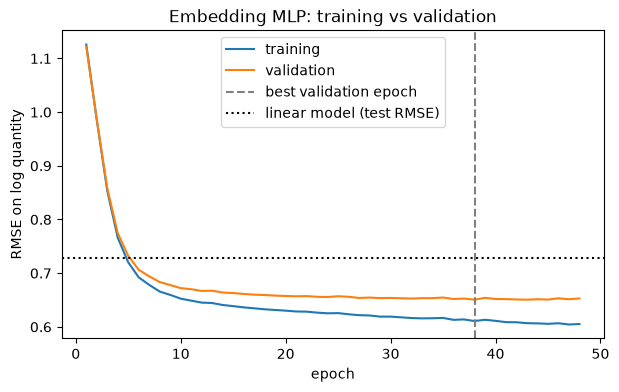

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
epochs = np.arange(1, len(emb_history["train"]) + 1)
ax.plot(epochs, emb_history["train"], label="training")
ax.plot(epochs, emb_history["val"], label="validation")
ax.axvline(np.argmin(emb_history["val"]) + 1, color="gray", linestyle="--", label="best validation epoch")
ax.axhline(0.728, color="black", linestyle=":", label="linear model (test RMSE)")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE on log quantity")
ax.set_title("Embedding MLP: training vs validation")
ax.legend()
plt.show()

It starts doing better on the training set than the validation set, but we continue until performance on the validation set seems to stop improving, rather than immediately once they separate.

In [13]:
# model evaluation

emb_model.eval()
with torch.no_grad():
    predictions["embedding MLP"] = emb_model(stock_idx["test"], cust_idx["test"]).numpy()
    emb_train_pred = emb_model(stock_idx["train"], cust_idx["train"]).numpy()

for name, pred in predictions.items():
    rmse = log_rmse(y_test, pred)
    mae_units = np.mean(np.abs(test_df["Quantity"] - np.exp(pred)))
    print(f"{name}: log RMSE {rmse:.3f} (typical factor {np.exp(rmse):.2f}) | MAE {mae_units:.2f} units")

print(f"\nembedding MLP on TRAINING data: log RMSE {log_rmse(y_train, emb_train_pred):.3f}")


baseline (training mean): log RMSE 1.206 (typical factor 3.34) | MAE 10.21 units
linear, target-encoded: log RMSE 0.728 (typical factor 2.07) | MAE 7.07 units
embedding MLP: log RMSE 0.655 (typical factor 1.92) | MAE 6.21 units

embedding MLP on TRAINING data: log RMSE 0.611


This model performs better than the linear model of part b, but is also much more flexible and computationally expensive.

### d: Neural net with an embedding layer and target encoding

We use the same target encoding as in part b, same loss function as always, and same training parameters as in part c.

In [14]:
# standardize the encodings of the stock code and customer ID

enc_mean, enc_sd = X_train.mean(), X_train.std()
enc_t = {name: torch.tensor(((X - enc_mean) / enc_sd).to_numpy(), dtype=torch.float32)
         for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]}

print("training encodings after standardizing: mean", enc_t["train"].mean(0).numpy().round(3),
      "| sd", enc_t["train"].std(0).numpy().round(3))

training encodings after standardizing: mean [-0. -0.] | sd [1. 1.]


In [15]:
class EmbeddingEncodingMLP(nn.Module):
    """Like EmbeddingMLP, but the two standardized target encodings are concatenated with the embeddings."""
    def __init__(self, n_stock, n_cust, emb_dim=8, hidden=(64, 64), n_enc=2):
        super().__init__()
        self.stock_emb = nn.Embedding(n_stock, emb_dim, padding_idx=0)
        self.cust_emb = nn.Embedding(n_cust, emb_dim, padding_idx=0)
        layers = []
        d = 2 * emb_dim + n_enc
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, stock, cust, enc):
        x = torch.cat([self.stock_emb(stock), self.cust_emb(cust), enc], dim=1)   # shape [n, 18]
        return self.net(x).squeeze(1)

In [16]:
combo_inputs = {split: (stock_idx[split], cust_idx[split], enc_t[split]) for split in splits}
combo_model, combo_history = train_model(lambda: EmbeddingEncodingMLP(len(stock_vocab) + 1, len(cust_vocab) + 1),
                                         combo_inputs)

stopped after 39 epochs | best validation RMSE 0.649 at epoch 29


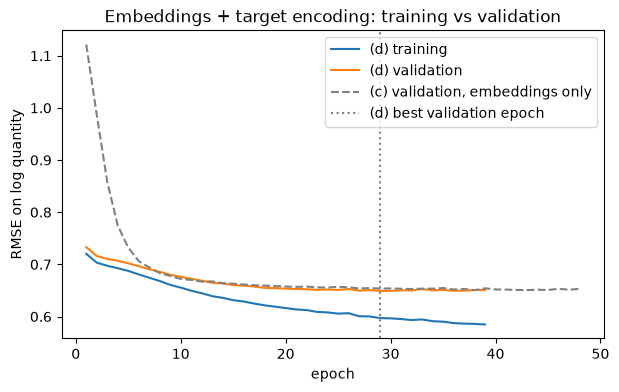

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(combo_history["train"]) + 1), combo_history["train"], label="(d) training")
ax.plot(np.arange(1, len(combo_history["val"]) + 1), combo_history["val"], label="(d) validation")
ax.plot(np.arange(1, len(emb_history["val"]) + 1), emb_history["val"], linestyle="--", color="gray",
        label="(c) validation, embeddings only")
ax.axvline(np.argmin(combo_history["val"]) + 1, color="gray", linestyle=":", label="(d) best validation epoch")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE on log quantity")
ax.set_title("Embeddings + target encoding: training vs validation")
ax.legend()
plt.show()

The loss here starts out much lower, because the model already has learned information at the onset with the extra two input features - the model weights learn these quickly. As training continues, though, this extra information offers barely any improvement over the embedding model without target encoding on the validation dataset.

In [18]:
# test set performance

combo_model.eval()
with torch.no_grad():
    predictions["embeddings + encodings MLP"] = combo_model(*combo_inputs["test"]).numpy()
    combo_train_pred = combo_model(*combo_inputs["train"]).numpy()

for name, pred in predictions.items():
    rmse = log_rmse(y_test, pred)
    mae_units = np.mean(np.abs(test_df["Quantity"] - np.exp(pred)))
    print(f"{name}: log RMSE {rmse:.3f} (typical factor {np.exp(rmse):.2f}) | MAE {mae_units:.2f} units")

print(f"\nembeddings + encodings MLP on TRAINING data: log RMSE {log_rmse(y_train, combo_train_pred):.3f}")

baseline (training mean): log RMSE 1.206 (typical factor 3.34) | MAE 10.21 units
linear, target-encoded: log RMSE 0.728 (typical factor 2.07) | MAE 7.07 units
embedding MLP: log RMSE 0.655 (typical factor 1.92) | MAE 6.21 units
embeddings + encodings MLP: log RMSE 0.649 (typical factor 1.91) | MAE 6.09 units

embeddings + encodings MLP on TRAINING data: log RMSE 0.597


This is also far better than the linear model.

### e: Analysis of results - what does the embedding layer do? Why might it be useful in this context?

General intuition: target encoding seems to give an initial boost to learning, but its overall effect seems to be capped and less than the more flexible embedding method. Embedding, then, is a way of capturing more information about the model than just target encoding.

#### Encoding-only MLP (no embedding)

This is to test whether it's a model family difference or an embedding versus target encoding difference that's causing the varying performances.

Training: same parameters as before!

In [19]:
class EncodingMLP(nn.Module):
    """MLP on the 2 standardized target encodings only, with no embeddings."""
    def __init__(self, n_enc=2, hidden=(64, 64)):
        super().__init__()
        layers = []
        d = n_enc
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, enc):
        return self.net(enc).squeeze(1)


enc_only_inputs = {split: (enc_t[split],) for split in splits}
enc_only_model, enc_only_history = train_model(lambda: EncodingMLP(), enc_only_inputs)

stopped after 47 epochs | best validation RMSE 0.707 at epoch 45


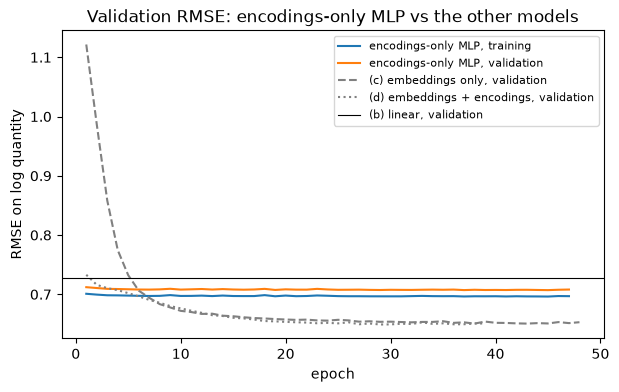

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(enc_only_history["train"]) + 1), enc_only_history["train"], label="encodings-only MLP, training")
ax.plot(np.arange(1, len(enc_only_history["val"]) + 1), enc_only_history["val"], label="encodings-only MLP, validation")
for history, name, style in [(emb_history, "(c) embeddings only", "--"),
                             (combo_history, "(d) embeddings + encodings", ":")]:
    ax.plot(np.arange(1, len(history["val"]) + 1), history["val"], linestyle=style, color="gray", label=f"{name}, validation")
ax.axhline(log_rmse(y_val, linear.predict(X_val)), color="black", linewidth=0.8,
           label="(b) linear, validation")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE on log quantity")
ax.set_title("Validation RMSE: encodings-only MLP vs the other models")
ax.legend(fontsize=8)
plt.show()

In [21]:
# test

enc_only_model.eval()
with torch.no_grad():
    predictions["encodings-only MLP"] = enc_only_model(*enc_only_inputs["test"]).numpy()
    enc_only_train_pred = enc_only_model(*enc_only_inputs["train"]).numpy()

for name, pred in predictions.items():
    rmse = log_rmse(y_test, pred)
    mae_units = np.mean(np.abs(test_df["Quantity"] - np.exp(pred)))
    print(f"{name}: log RMSE {rmse:.3f} (typical factor {np.exp(rmse):.2f}) | MAE {mae_units:.2f} units")

print(f"\nencodings-only MLP on TRAINING data: log RMSE {log_rmse(y_train, enc_only_train_pred):.3f}")

baseline (training mean): log RMSE 1.206 (typical factor 3.34) | MAE 10.21 units
linear, target-encoded: log RMSE 0.728 (typical factor 2.07) | MAE 7.07 units
embedding MLP: log RMSE 0.655 (typical factor 1.92) | MAE 6.21 units
embeddings + encodings MLP: log RMSE 0.649 (typical factor 1.91) | MAE 6.09 units
encodings-only MLP: log RMSE 0.708 (typical factor 2.03) | MAE 6.74 units

encodings-only MLP on TRAINING data: log RMSE 0.696


This method beats the linear model from part b, but still does significantly worse than the two embedding models from c and d. Hence, while the embedding models are slower to train, they have a much higher ceiling in their ability to learn the desired patterns from the data.

In [22]:
def rmse_by_frequency(col):
    """Test RMSE per model, with test rows grouped by how many training rows their category in `col` has."""
    train_counts = train_df[col].astype(str).value_counts()
    n_train = test_df[col].astype(str).map(train_counts).fillna(0).to_numpy()
    bins = pd.cut(n_train, bins=[-1, 0, 5, 20, 100, 500, np.inf],
                  labels=["unseen", "1-5", "6-20", "21-100", "101-500", "500+"])

    df = pd.DataFrame({"bin": bins})
    for name, pred in predictions.items():
        df[name] = (y_test.to_numpy() - pred) ** 2
    table = df.groupby("bin", observed=False).mean() ** 0.5
    table.insert(0, "test rows", df.groupby("bin", observed=False).size())
    return table.round(3)

print("Grouped by StockCode frequency in training:")
display(rmse_by_frequency("StockCode"))
print("Grouped by CustomerID frequency in training:")
display(rmse_by_frequency("CustomerID"))

Grouped by StockCode frequency in training:


,test rows,baseline (training mean),"linear, target-encoded",embedding MLP,embeddings + encodings MLP,encodings-only MLP
bin,,,,,,
unseen,17,1.270,0.712,0.793,0.595,0.729
1-5,180,1.360,0.958,0.904,0.844,0.959
6-20,1073,1.271,0.805,0.683,0.698,0.810
21-100,8716,1.234,0.740,0.676,0.672,0.722
101-500,23234,1.190,0.714,0.641,0.635,0.692
500+,6573,1.210,0.740,0.660,0.656,0.718


Grouped by CustomerID frequency in training:


,test rows,baseline (training mean),"linear, target-encoded",embedding MLP,embeddings + encodings MLP,encodings-only MLP
bin,,,,,,
unseen,14,2.448,2.190,3.513,2.608,2.125
1-5,228,1.537,1.203,0.891,0.919,1.166
6-20,1783,1.197,0.802,0.601,0.616,0.768
21-100,11926,1.164,0.701,0.612,0.615,0.680
101-500,18820,1.169,0.689,0.624,0.618,0.670
500+,7022,1.354,0.822,0.778,0.766,0.803


It seems like the embeddings are almost always helpful, even in the rare cases (the unseen rows are few, so higher-variance). Perhaps the encodings don't take into account the smaller groups' specificities enough and put too much weight on the overall mean.

#### Embedding with only 1 dimension

In [23]:
emb1_model, emb1_history = train_model(
    lambda: EmbeddingMLP(len(stock_vocab) + 1, len(cust_vocab) + 1, emb_dim=1), emb_inputs)

emb1_model.eval()
with torch.no_grad():
    predictions["embedding MLP, dim 1"] = emb1_model(*emb_inputs["test"]).numpy()
    emb1_train_pred = emb1_model(*emb_inputs["train"]).numpy()

for name, pred in predictions.items():
    rmse = log_rmse(y_test, pred)
    mae_units = np.mean(np.abs(test_df["Quantity"] - np.exp(pred)))
    print(f"{name}: log RMSE {rmse:.3f} (typical factor {np.exp(rmse):.2f}) | MAE {mae_units:.2f} units")

print(f"\nembedding MLP, dim 1 on TRAINING data: log RMSE {log_rmse(y_train, emb1_train_pred):.3f}")

stopped after 50 epochs | best validation RMSE 0.663 at epoch 40
baseline (training mean): log RMSE 1.206 (typical factor 3.34) | MAE 10.21 units
linear, target-encoded: log RMSE 0.728 (typical factor 2.07) | MAE 7.07 units
embedding MLP: log RMSE 0.655 (typical factor 1.92) | MAE 6.21 units
embeddings + encodings MLP: log RMSE 0.649 (typical factor 1.91) | MAE 6.09 units
encodings-only MLP: log RMSE 0.708 (typical factor 2.03) | MAE 6.74 units
embedding MLP, dim 1: log RMSE 0.663 (typical factor 1.94) | MAE 6.45 units

embedding MLP, dim 1 on TRAINING data: log RMSE 0.643


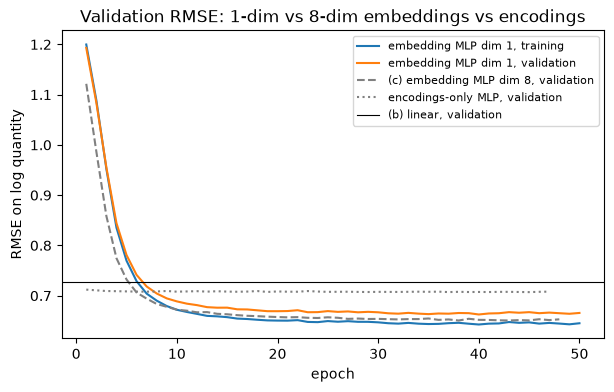

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(emb1_history["train"]) + 1), emb1_history["train"], label="embedding MLP dim 1, training")
ax.plot(np.arange(1, len(emb1_history["val"]) + 1), emb1_history["val"], label="embedding MLP dim 1, validation")
for history, name, style in [(emb_history, "(c) embedding MLP dim 8", "--"),
                             (enc_only_history, "encodings-only MLP", ":")]:
    ax.plot(np.arange(1, len(history["val"]) + 1), history["val"], linestyle=style, color="gray", label=f"{name}, validation")
ax.axhline(log_rmse(y_val, linear.predict(X_val)), color="black", linewidth=0.8, label="(b) linear, validation")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE on log quantity")
ax.set_title("Validation RMSE: 1-dim vs 8-dim embeddings vs encodings")
ax.legend(fontsize=8)
plt.show()

It seems like the advantage of the embedding goes even beyond the number of dimensions - it just gives the model much more flexibility in determining the value associated to each stock code / customer ID, and hence the ability to learn more and perform better!